# 3D-ΔPDF by Fourier transform: a synthetic example

**This is a synthetic volume, not DISCUS output.** A quantitative 3D-ΔPDF requires a Bragg-subtracted diffuse intensity volume on a corrected, centered Cartesian Q grid; Bragg subtraction, masking, normalization, and voxel interpolation are outside this starter.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from discuspdf import delta_pdf_from_diffuse, plot_delta_pdf_slice, FFTValidationError

## 1. Construct a synthetic centrosymmetric diffuse intensity

Coordinates below are in physical Q units Å⁻¹.

In [2]:
n = 64
dq = 0.15  # Å^-1
q = (np.arange(n) - n//2) * dq
qx, qy, qz = np.meshgrid(q, q, q, indexing="ij")
# An example smooth, nonnegative centrosymmetric feature
i_diff = np.exp(-((qx-1.1)**2+qy**2+qz**2)/(2*0.35**2))
i_diff += np.exp(-((qx+1.1)**2+qy**2+qz**2)/(2*0.35**2))

## 2. Transform to a real-space 3D-ΔPDF

FFTDiagnostics(imaginary_ratio=1.1410716794337586e-16, max_imaginary=3.597099718310513e-19, max_real=0.005444579281361164, friedel_relative_error=0.0, dq=(0.15, 0.15, 0.15), reciprocal_voxel_volume=0.003375, normalization='dQx*dQy*dQz/(2*pi)^3; exp(-i Q.r)')


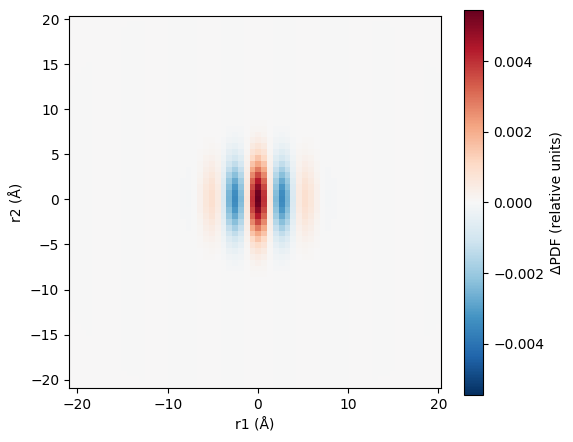

In [3]:
# delta_pdf_from_diffuse — FFT of a Bragg-subtracted 3D diffuse volume to real space (3D-ΔPDF)
#   diffuse_intensity    finite 3D array (or a ReciprocalVolume, then omit q_axes)
#   q_axes               three 1D Q axes in Å⁻¹, uniform, centered: q[i] = (i - n//2)·dq, lengths = array shape
#   imaginary_tolerance  max allowed imaginary/real norm ratio, >= 0 (default 1e-4)
#   raise_on_imaginary   True (default): ratio above tolerance raises FFTValidationError (exc.result holds
#                        the computed FFTResult); False: RuntimeWarning instead
#   normalization        exp(-i Q·r), scaled by dQx·dQy·dQz/(2π)³
#   returns              FFTResult: .complex_volume, .real_volume, .r_axes (Å, 2π·fftfreq),
#                        .diagnostics (imaginary_ratio, friedel_relative_error, dq, ...)
fft = delta_pdf_from_diffuse(i_diff, (q, q, q))
print(fft.diagnostics)
delta, r_axes = fft.real_volume, fft.r_axes
# plot_delta_pdf_slice — image of one 2D slice through a 3D ΔPDF volume
#   volume, r_axes   3D array and its three r axes (Å)
#   axis             axis normal to the slice: 0, 1 or 2 (default 2)
#   index            slice index along that axis (default: centre, shape[axis] // 2)
#   returns          the Axes (symmetric RdBu_r colour scale with colourbar)
ax = plot_delta_pdf_slice(delta, r_axes, axis=2)
plt.show()

## 3. Replace synthetic data with your own

For an HDF5 file, identify the actual dataset paths first. **Do not assume** a universal DISCUS HDF5 layout.

```python
from discuspdf import read_hdf5_volume, delta_pdf_from_diffuse, FFTValidationError
intensity, q_axes = read_hdf5_volume(
    "your_diffuse_volume.h5",
    intensity_dataset="/actual/intensity/path",
    q_datasets=("/actual/qx/path", "/actual/qy/path", "/actual/qz/path"),
)
try:
    fft = delta_pdf_from_diffuse(intensity, q_axes)
except FFTValidationError as exc:
    print(exc.result.diagnostics)  # the computed FFT is preserved on the exception
else:
    delta, r_axes = fft.real_volume, fft.r_axes
```

If the source uses h,k,l reciprocal-lattice coordinates, first map the data to an appropriately sampled Cartesian Q grid using the reciprocal-cell metric. This notebook never runs a real DISCUS 3D computation; see `docs/3D_INTEGRATION.md` for the runner workflow.

## 4. Radiation and wavelength for DISCUS 3D runs

When the diffuse volume comes from DISCUS, `FourierConfig` writes the `fourier` part of the macro. It
chooses the **radiation** (`"xray"` or `"neutron"`) and the **wavelength**, like `PDFConfig` does for
the 1D PDF:

| Option | Values | Macro lines |
|---|---|---|
| `radiation` | `"xray"` (default), `"neutron"` | `xray` / `neut` |
| `wavelength` | a DISCUS symbol (`"moa1"` default, `"cua1"`, `"aga1"`, `"mob"`, … — `WAVELENGTHS`) or a number in Å | `wvle moa1` / `wvle 1.54` |

Nothing below runs DISCUS: the macros are only rendered, and the results shown are DISCUS 6.23.01 runs
already in the repository (`benchmarks/discus_6_23_01/d_reference/`, a Cu/Au fcc crystal of 4×4×4 cells).
See `docs/FOURIER_CONTROLS.md` for the full list of options.

In [4]:
from pathlib import Path
from discuspdf import Lattice, ReciprocalGrid, FourierConfig, StructureSource, ScatteringVolume
from discuspdf.fourier_macro import WAVELENGTHS

ROOT = next(d for d in (Path.cwd(), *Path.cwd().parents) if (d / "benchmarks").is_dir())
DREF = ROOT / "benchmarks/discus_6_23_01/d_reference"
WORK = DREF / "evidence/20261101T221751Z_LAPTOP-NGU3BT0N/work"

# the grid of the recorded runs: h, k from -2 to 2 and l from 0 to 2 in steps of 1/4, on a 3.75 Å cubic cell
lat = Lattice.from_parameters(3.75, 3.75, 3.75, 90, 90, 90)
grid = ReciprocalGrid.from_ranges(lat, (-2, 2, 17), (-2, 2, 17), (0, 2, 9))

# FourierConfig — one DISCUS single-crystal Fourier calculation
#   grid          ReciprocalGrid (gives ll/lr/ul/tl/na/no/nt)
#   outputs       ((value, file.h5), ...), value in int / real / imag / 3DPDF
#   aver_percent  set aver: 0 keeps the Bragg peaks, 100 subtracts the average structure exactly
#   temperature   'ignore' or 'use' (Debye–Waller factor from the B values)
#   radiation     'xray' (default) or 'neutron'
#   wavelength    DISCUS symbol (default 'moa1') or a number in Å
def config(run_id, radiation, **kw):
    return FourierConfig(grid, outputs=(("int", f"{run_id}.h5"),), aver_percent=100, temperature="use",
                         radiation=radiation, **kw)

for cfg in (config("x", "xray"), config("n", "neutron"), config("n", "neutron", wavelength=1.54),
            config("x", "xray", wavelength="CuA1")):
    print(cfg.radiation, repr(cfg.wavelength), "->", cfg.fourier_lines()[1:3])
print(len(WAVELENGTHS), "symbols, e.g.", WAVELENGTHS[12:18])

xray 'moa1' -> ['  xray', '  wvle moa1']
neutron 'moa1' -> ['  neut', '  wvle moa1']
neutron 1.54 -> ['  neut', '  wvle 1.54']
xray 'cua1' -> ['  xray', '  wvle cua1']
30 symbols, e.g. ('cua1', 'cua2', 'cub', 'moa1', 'moa2', 'mob')


The radiation line always comes before `wvle`, because DISCUS's `neut` command clears a wavelength
symbol set earlier. Symbols are stored in lower case. Settings DISCUS would not accept are refused before
any macro is written:

In [5]:
for bad in (dict(radiation="electron"), dict(wavelength="cuka"), dict(wavelength=0.0)):
    try:
        FourierConfig(grid, outputs=(("int", "a.h5"),), **bad)
    except ValueError as exc:
        print(f"{bad}: {exc}")

{'radiation': 'electron'}: radiation must be one of ('xray', 'neutron')
{'wavelength': 'cuka'}: wavelength symbol 'cuka' is not a DISCUS 6.23.01 symbol ('tia1', 'tia2', 'tib', 'cra1', 'cra2', 'crb', 'fea1', 'fea2', 'feb', 'coa1', 'coa2', 'cob', 'cua1', 'cua2', 'cub', 'moa1', 'moa2', 'mob', 'aga1', 'aga2', 'agb', 'taa1', 'taa2', 'tab', 'wa1', 'wa2', 'wb', 'aua1', 'aua2', 'aub'); or give a number in Å
{'wavelength': 0.0}: wavelength must be finite and > 0 Å, got 0.0


### X-ray and neutron results for the same crystal

The recorded runs used these settings, with the Bragg peaks subtracted (`set aver,100`). The generated
`fourier` block is identical to the macro DISCUS ran (checked in `tests/test_fourier_radiation.py`).
Loading a file together with its configuration checks the radiation and wavelength that DISCUS wrote into
the file:

In [6]:
# ScatteringVolume.from_discus_file — read a DISCUS NeXus file
#   config   the FourierConfig that wrote it: grid, content, Bragg label, radiation and wavelength
#            are compared with the file, and a mismatch raises ValueError
xray = ScatteringVolume.from_discus_file(WORK / "cuau_x_dif_c4.h5", config=config("cuau_x_dif_c4", "xray"))
neut = ScatteringVolume.from_discus_file(WORK / "cuau_n_dif_c4.h5", config=config("cuau_n_dif_c4", "neutron"))
for name, v in (("X-ray", xray), ("neutron", neut)):
    m = v.provenance["discus_metadata"]
    print(f"{name:8s} file: radiation={m['data_radiation']!r}, symbol={m['data_rad_symbol']!r}")
try:
    ScatteringVolume.from_discus_file(WORK / "cuau_n_dif_c4.h5", config=config("cuau_n_dif_c4", "xray"))
except ValueError as exc:
    print("refused:", exc)

X-ray    file: radiation='xray', symbol='MOA1'
neutron  file: radiation='neutron', symbol='MOA1'
refused: cuau_n_dif_c4.h5: file radiation 'neutron' but the configuration used 'xray'


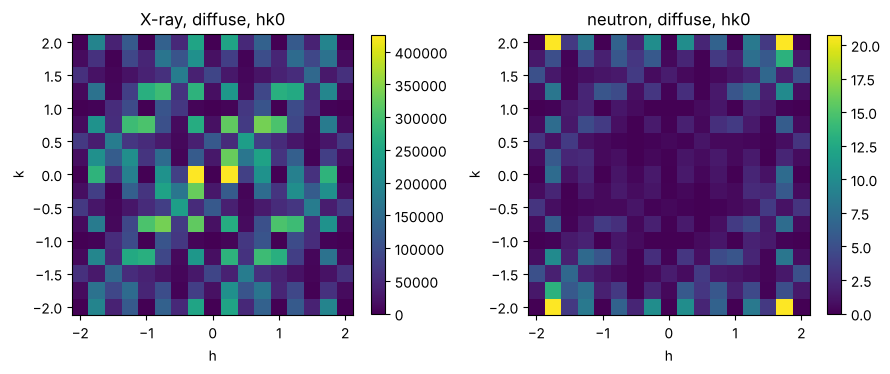

total diffuse intensity, X-ray / neutron = 21258


In [7]:
l0 = 0   # the l = 0 plane
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, (name, v) in zip(axes, (("X-ray", xray), ("neutron", neut))):
    im = ax.imshow(v.intensity[:, :, l0].T, origin="lower", extent=(-2.125, 2.125, -2.125, 2.125), cmap="viridis")
    ax.set(title=f"{name}, diffuse, hk0", xlabel="h", ylabel="k")
    fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()
print(f"total diffuse intensity, X-ray / neutron = {xray.intensity.sum() / neut.intensity.sum():.0f}")

Both maps show the same random Cu/Au crystal, but the patterns and the scales differ. The diffuse
intensity grows with the square of the contrast between the two species, f_Au·e^(−B_Au s²) − f_Cu·e^(−B_Cu s²)
with s = |Q|/4π (B = 0.8 and 0.5 Å² here). For X-rays the contrast is large (Au has 50 more electrons
than Cu) and falls off with |Q| like the form factors, so the X-ray map is strongest near the origin. For
neutrons the two coherent scattering lengths are almost equal (DISCUS uses 7.718 fm for Cu and 7.63 fm
for Au); the contrast comes mostly from the different B values and grows towards high |Q|, so the neutron
map is about 2 × 10⁴ times weaker overall and brightest at the corners.

**The wavelength does not change these intensities.** The macros always contain `disp off` (no anomalous
dispersion). In DISCUS 6.23.01 the Fourier calculation then uses λ only to label the output file
(`data_rad_symbol`, `data_rad_length`). X-ray form factors depend on sin θ/λ = |Q|/4π, not on λ, and
neutron scattering lengths are constants. A numeric `wvle` and symbols other than `moa1` are accepted by
the DISCUS source but have not been run in a recorded test yet.